# Employee Attrition Analysis & Prediction Using AI & Machine Learning

**Project**: Advanced Employee Attrition Analysis and Prediction Using AI & Machine Learning  **
**Author**: YourName  **
**Date**: October 10, 2026  **
**Audience**: AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026  **

**Educational notice**: This notebook uses fictional employee records from a public Kaggle dataset. It is NOT real IBM employee data. Statistical associations are not proof of causation, and any model built here is for learning only. It must not be used for real employment decisions.

---

## Contents

1. Environment setup & imports
2. Load and validate the dataset
3. Data cleaning decision log
4. Exploratory data analysis (EDA)
5. Feature engineering & preprocessing pipeline
6. Train / validation split
7. Model training & comparison
8. Evaluation on a held-out test set
9. Model interpretation
10. Save the best pipeline
11. Example prediction
12. Limitations & closing notes

---


In [1]:
# ============================================================
# STEP 0: Imports & project setup
# ============================================================
import pathlib
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    average_precision_score, roc_curve
)
from sklearn.inspection import permutation_importance

import joblib

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100

RANDOM_STATE = 42

print('All libraries imported successfully.')
print('pandas      :', pd.__version__)
print('numpy       :', np.__version__)
print('scikit-learn:', __import__('sklearn').__version__)
print('random_state used for splits / models:', RANDOM_STATE)


All libraries imported successfully.
pandas      : 2.2.2
numpy       : 2.2.6
scikit-learn: 1.4.2
random_state used for splits / models: 42


In [2]:
# ============================================================
# STEP 1: Locate and load the dataset
# ============================================================
def project_root():
    cwd = pathlib.Path.cwd()
    if cwd.name == 'notebooks' and (cwd.parent / 'data').exists():
        return cwd.parent
    return cwd

ROOT = project_root()
DATA_PATH = ROOT / 'data' / 'WA_Fn-UseC_-HR-Employee-Attrition.csv'

print('Project root detected :', ROOT)
print('Dataset path          :', DATA_PATH)
print('File exists           :', DATA_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f'Dataset not found at {DATA_PATH}.\n'
        'Expected layout:\n'
        '  Employee-Attrition-AI/\n'
        '  ├── data/\n'
        '  │   └── WA_Fn-UseC_-HR-Employee-Attrition.csv\n'
        '  └── notebooks/\n'
        '      └── YourName_Employee_Attrition_Analysis.ipynb\n'
        '\n'
        'Fix: place the CSV in data/ next to this notebook, or open the notebook\n'
        'from the project root so the path resolves correctly.'
    )

df = pd.read_csv(DATA_PATH)
print('\nDataset loaded.')
print('Shape (rows, columns) :', df.shape)


Project root detected : D:\Data Analyst\Employee-Attrition-AI
Dataset path          : D:\Data Analyst\Employee-Attrition-AI\data\WA_Fn-UseC_-HR-Employee-Attrition.csv
File exists           : True

Dataset loaded.
Shape (rows, columns) : (1470, 35)


In [3]:
# ============================================================
# STEP 2: Basic dataset inspection
# ============================================================
print('=' * 70)
print('DATASET OVERVIEW')
print('=' * 70)

print('\nShape (rows, columns):', df.shape)
print('\nColumns and data types:')
print(df.dtypes.to_string())
print('\nFirst 5 rows:')
print(df.head().to_string())
print('\nDescriptive statistics - numerical columns:')
print(df.describe().T.to_string())
print('\nDescriptive statistics - categorical columns:')
print(df.describe(include=['object', 'category']).T.to_string())
print('\nMissing values per column:')
missing = df.isnull().sum()
print(missing[missing > 0].to_string() if missing.sum() else 'No missing values found.')
print('\nTotal missing cells:', int(missing.sum()))
print('\nDuplicate rows:', int(df.duplicated().sum()))
print('\nTarget variable (Attrition) value counts:')
print(df['Attrition'].value_counts(dropna=False).to_string())
print('\nAttrition rate: {:.2f}%'.format(df['Attrition'].eq('Yes').mean() * 100))


DATASET OVERVIEW

Shape (rows, columns): (1470, 35)

Columns and data types:
Age                          int64
Attrition                   object
BusinessTravel              object
DailyRate                    int64
Department                  object
DistanceFromHome             int64
Education                    int64
EducationField              object
EmployeeCount                int64
EmployeeNumber               int64
EnvironmentSatisfaction      int64
Gender                      object
HourlyRate                   int64
JobInvolvement               int64
JobLevel                     int64
JobRole                     object
JobSatisfaction              int64
MaritalStatus               object
MonthlyIncome                int64
MonthlyRate                  int64
NumCompaniesWorked           int64
Over18                      object
OverTime                    object
PercentSalaryHike            int64
PerformanceRating            int64
RelationshipSatisfaction     int64
StandardHours

In [4]:
# ============================================================
# STEP 3: Data cleaning decision log
# ============================================================
print('=' * 70)
print('DATA CLEANING DECISIONS')
print('=' * 70)

print('\n1) Duplicate rows')
n_dupes = int(df.duplicated().sum())
print('   Found:', n_dupes)
if n_dupes:
    print('   Decision: drop exact duplicates once.')
    df_clean = df.drop_duplicates().copy()
else:
    df_clean = df.copy()
    print('   Decision: none found, so no rows removed.')

print('\n2) Constant / effectively useless columns')
constant_cols = [c for c in df_clean.columns if df_clean[c].nunique() <= 1]
print('   Constant columns:', constant_cols)
for c in constant_cols:
    print(f'     - {c}: {df_clean[c].unique().tolist()}')

print('\n3) Identifier columns')
id_like = [c for c in df_clean.columns if 'Id' in c or 'Number' in c or c.lower() == 'employeenumber']
print('   Candidate identifier columns:', id_like)
for c in id_like:
    nun = df_clean[c].nunique()
    nrow = len(df_clean)
    print(f'     - {c}: unique={nun}, rows={nrow}, unique_ratio={nun/max(nrow,1):.3f}')

print('\n4) Target column sanity check')
print('   Expected target: Attrition with Yes/No labels.')
target_values = df_clean['Attrition'].dropna().unique().tolist()
print('   Observed Attrition values:', sorted(target_values))
assert set(target_values) <= {'Yes', 'No'}, 'Unexpected Attrition labels found.'
print('   OK: target is binary Yes/No.')

print('\nFinal cleaned DataFrame shape:', df_clean.shape)


DATA CLEANING DECISIONS

1) Duplicate rows
   Found: 0
   Decision: none found, so no rows removed.

2) Constant / effectively useless columns
   Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
     - EmployeeCount: [1]
     - Over18: ['Y']
     - StandardHours: [80]

3) Identifier columns
   Candidate identifier columns: ['EmployeeNumber']
     - EmployeeNumber: unique=1470, rows=1470, unique_ratio=1.000

4) Target column sanity check
   Expected target: Attrition with Yes/No labels.
   Observed Attrition values: ['No', 'Yes']
   OK: target is binary Yes/No.

Final cleaned DataFrame shape: (1470, 35)


In [5]:
# ============================================================
# STEP 4a: Define columns we will treat as identifiers / exclude
# ============================================================
ID_COLUMNS = []
for c in df_clean.columns:
    nun = df_clean[c].nunique()
    if nun == len(df_clean):
        ID_COLUMNS.append(c)

print('Columns treated as row identifiers and excluded from model inputs:')
for c in ID_COLUMNS:
    print('  -', c)

print('\nIf a column is a near-identifier but not perfectly unique, we still')
print('review it manually in the EDA section below.')


Columns treated as row identifiers and excluded from model inputs:
  - EmployeeNumber

If a column is a near-identifier but not perfectly unique, we still
review it manually in the EDA section below.


In [6]:
# ============================================================
# STEP 4b: Overall attrition summary
# ============================================================
n_total = len(df_clean)
n_left = int((df_clean['Attrition'] == 'Yes').sum())
n_stayed = n_total - n_left
attrition_rate = n_left / n_total * 100

summary = pd.DataFrame({
    'Metric': ['Total employees', 'Employees who left (Attrition=Yes)',
               'Employees who stayed (Attrition=No)', 'Overall attrition rate (%)'],
    'Value':  [n_total, n_left, n_stayed, round(attrition_rate, 2)]
})

print(summary.to_string(index=False))

print('\nInterpretation:')
print('  The dataset is imbalanced: far fewer employees left than stayed.')
print('  Because of that, accuracy alone is a weak measure of model quality.')
print('  We will also examine precision, recall, F1, and ROC-AUC.')


                             Metric   Value
                    Total employees 1470.00
 Employees who left (Attrition=Yes)  237.00
Employees who stayed (Attrition=No) 1233.00
         Overall attrition rate (%)   16.12

Interpretation:
  The dataset is imbalanced: far fewer employees left than stayed.
  Because of that, accuracy alone is a weak measure of model quality.
  We will also examine precision, recall, F1, and ROC-AUC.


Attrition share by department:
Attrition                     No  Left_pct  total_employees
Department                                                 
Sales                   0.793722  0.206278              446
Human Resources         0.809524  0.190476               63
Research & Development  0.861602  0.138398              961


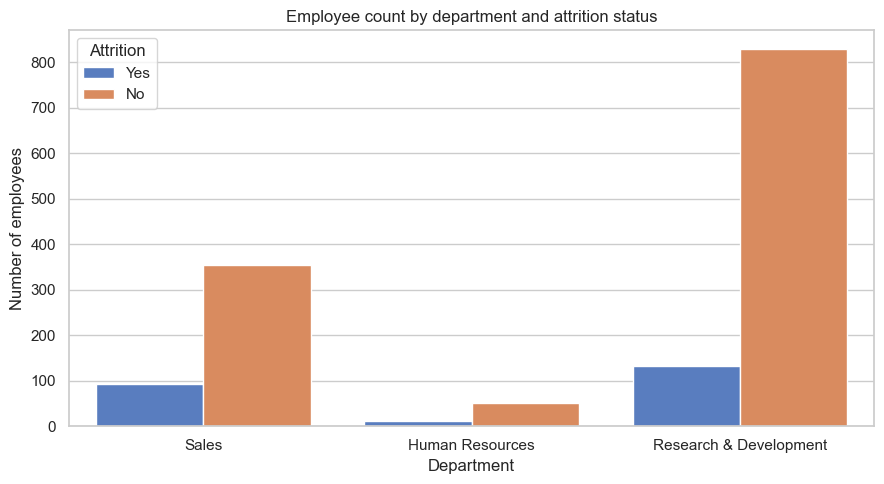

Interpretation:
  This chart shows counts, not just rates. A department can have many leavers
  simply because it has many employees. Compare the rate table above with this
  count chart when reading the result.


In [7]:
# ============================================================
# STEP 4c: Attrition by department
# ============================================================
dept_attr = (
    df_clean.groupby('Department')['Attrition']
    .value_counts(normalize=True)
    .unstack(fill_value=0)
    .assign(total_employees=lambda x: df_clean['Department'].value_counts())
    [['No', 'Yes', 'total_employees']]
    .rename(columns={'}No{': 'Stayed_pct', 'Yes': 'Left_pct'})
    .sort_values('Left_pct', ascending=False)
)

print('Attrition share by department:')
print(dept_attr.to_string())

fig, ax = plt.subplots(figsize=(9, 5))
order = dept_attr.index.tolist()
sns.countplot(data=df_clean, x='Department', hue='Attrition', order=order, ax=ax)
ax.set_title('Employee count by department and attrition status')
ax.set_xlabel('Department')
ax.set_ylabel('Number of employees')
ax.legend(title='Attrition')
plt.tight_layout()
plt.show()

print('Interpretation:')
print('  This chart shows counts, not just rates. A department can have many leavers')
print('  simply because it has many employees. Compare the rate table above with this')
print('  count chart when reading the result.')


Attrition share by job role:
Attrition                        No  Left_pct  total_employees
JobRole                                                       
Sales Representative       0.602410  0.397590               83
Laboratory Technician      0.760618  0.239382              259
Human Resources            0.769231  0.230769               52
Sales Executive            0.825153  0.174847              326
Research Scientist         0.839041  0.160959              292
Manufacturing Director     0.931034  0.068966              145
Healthcare Representative  0.931298  0.068702              131
Manager                    0.950980  0.049020              102
Research Director          0.975000  0.025000               80


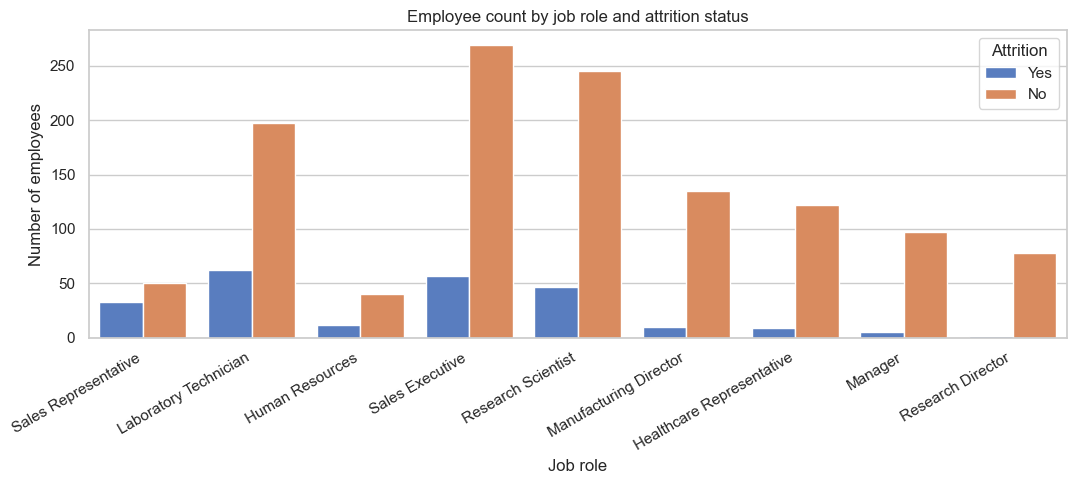

Interpretation:
  Some roles show a higher share of leavers. As before, counts and rates can
  point in different directions, so we read both together.


In [8]:
# ============================================================
# STEP 4d: Attrition by job role
# ============================================================
role_attr = (
    df_clean.groupby('JobRole')['Attrition']
    .value_counts(normalize=True)
    .unstack(fill_value=0)
    .assign(total_employees=lambda x: df_clean['JobRole'].value_counts())
    [['No', 'Yes', 'total_employees']]
    .rename(columns={'}No{': 'Stayed_pct', 'Yes': 'Left_pct'})
    .sort_values('Left_pct', ascending=False)
)

print('Attrition share by job role:')
print(role_attr.to_string())

fig, ax = plt.subplots(figsize=(11, 5))
order = role_attr.index.tolist()
sns.countplot(data=df_clean, x='JobRole', hue='Attrition', order=order, ax=ax)
ax.set_title('Employee count by job role and attrition status')
ax.set_xlabel('Job role')
ax.set_ylabel('Number of employees')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
ax.legend(title='Attrition')
plt.tight_layout()
plt.show()

print('Interpretation:')
print('  Some roles show a higher share of leavers. As before, counts and rates can')
print('  point in different directions, so we read both together.')


Attrition share by overtime status:
Attrition        No  Left_pct  total_employees
OverTime                                      
Yes        0.694712  0.305288              416
No         0.895636  0.104364             1054


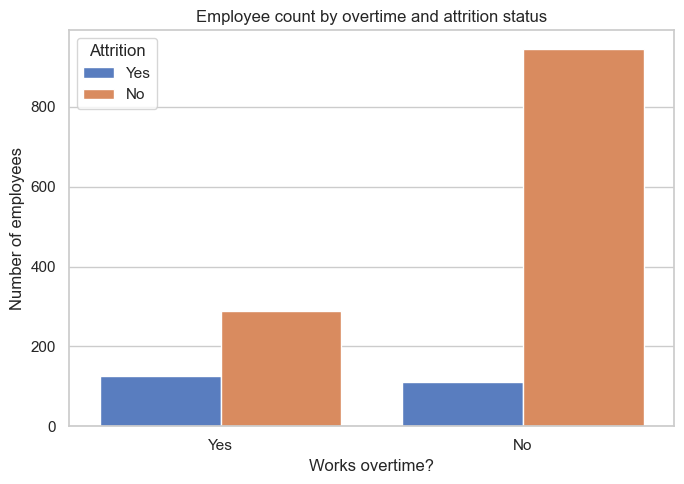

Interpretation:
  Overtime is one of the clearer associations in this dataset: employees who
  work overtime show a higher left share than those who do not. This is an
  association, not proof that overtime causes attrition.


In [9]:
# ============================================================
# STEP 4e: Attrition and overtime
# ============================================================
ot_attr = (
    df_clean.groupby('OverTime')['Attrition']
    .value_counts(normalize=True)
    .unstack(fill_value=0)
    .assign(total_employees=lambda x: df_clean['OverTime'].value_counts())
    [['No', 'Yes', 'total_employees']]
    .rename(columns={'}No{': 'Stayed_pct', 'Yes': 'Left_pct'})
    .reindex(['Yes', 'No'])
)

print('Attrition share by overtime status:')
print(ot_attr.to_string())

fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=df_clean, x='OverTime', hue='Attrition', ax=ax)
ax.set_title('Employee count by overtime and attrition status')
ax.set_xlabel('Works overtime?')
ax.set_ylabel('Number of employees')
ax.legend(title='Attrition')
plt.tight_layout()
plt.show()

print('Interpretation:')
print('  Overtime is one of the clearer associations in this dataset: employees who')
print('  work overtime show a higher left share than those who do not. This is an')
print('  association, not proof that overtime causes attrition.')


Attrition share by age group:
Attrition        No  Left_pct  total_employees
AgeGroup                                      
<25        0.608247  0.391753               97
25-35      0.797834  0.202166              554
35-45      0.899010  0.100990              505
45-55      0.897959  0.102041              245
55+        0.840580  0.159420               69


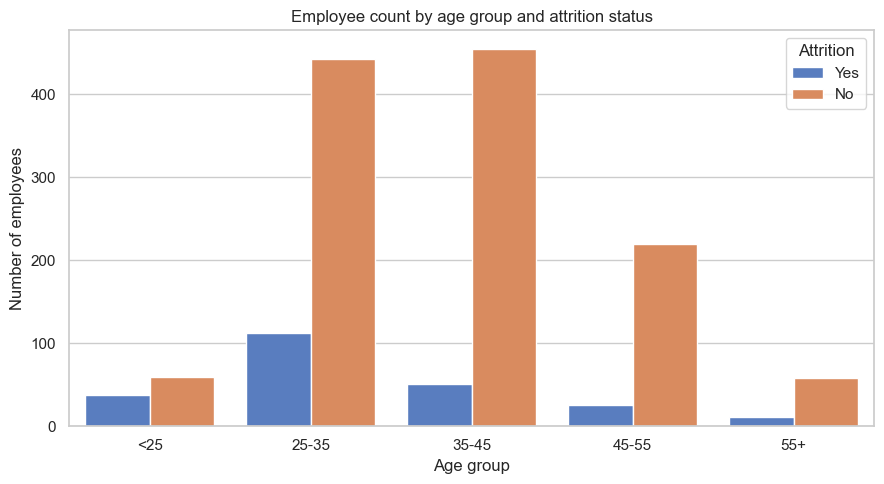

Interpretation:
  Attrition is not evenly spread across age. Younger age bands often show a
  higher left share in this kind of dataset, but again this is association,
  not a rule about any particular person.


In [10]:
# ============================================================
# STEP 4f: Attrition by age group
# ============================================================
df_clean['AgeGroup'] = pd.cut(
    df_clean['Age'],
    bins=[0, 25, 35, 45, 55, 100],
    labels=['<25', '25-35', '35-45', '45-55', '55+'],
    right=False,
)

age_attr = (
    df_clean.groupby('AgeGroup', observed=True)['Attrition']
    .value_counts(normalize=True)
    .unstack(fill_value=0)
    .assign(total_employees=lambda x: df_clean['AgeGroup'].value_counts())
    [['No', 'Yes', 'total_employees']]
    .rename(columns={'}No{': 'Stayed_pct', 'Yes': 'Left_pct'})
)

print('Attrition share by age group:')
print(age_attr.to_string())

fig, ax = plt.subplots(figsize=(9, 5))
order = age_attr.index.astype(str).tolist()
sns.countplot(data=df_clean, x='AgeGroup', hue='Attrition', order=order, ax=ax)
ax.set_title('Employee count by age group and attrition status')
ax.set_xlabel('Age group')
ax.set_ylabel('Number of employees')
ax.legend(title='Attrition')
plt.tight_layout()
plt.show()

print('Interpretation:')
print('  Attrition is not evenly spread across age. Younger age bands often show a')
print('  higher left share in this kind of dataset, but again this is association,')
print('  not a rule about any particular person.')


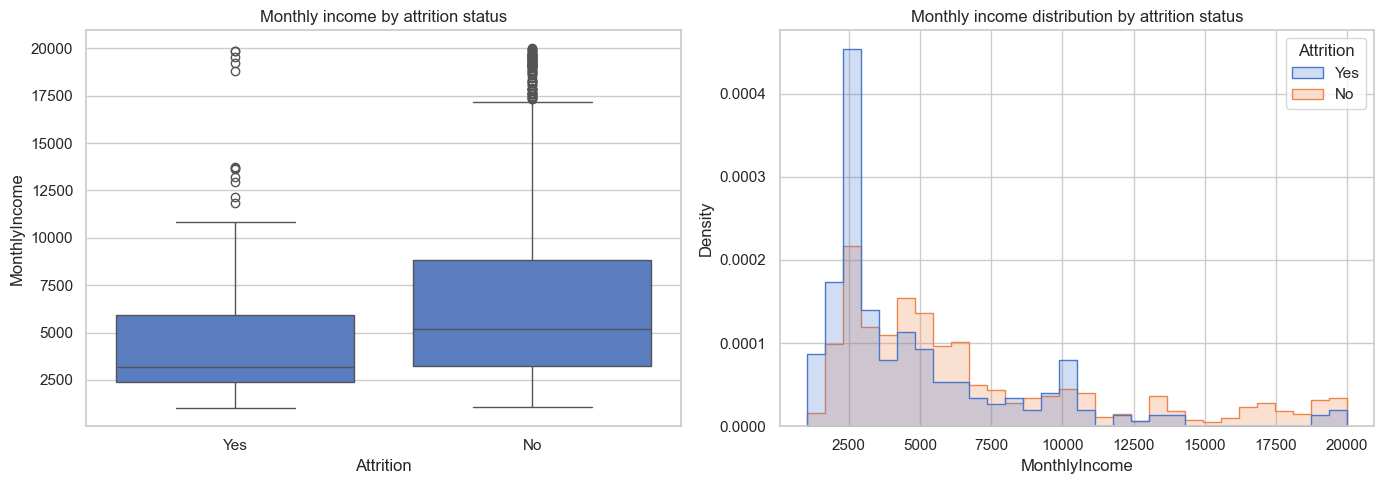

Summary statistics by attrition group:
Attrition            No           Yes
count       1233.000000    237.000000
mean        6832.739659   4787.092827
std         4818.208001   3640.210367
min         1051.000000   1009.000000
25%         3211.000000   2373.000000
50%         5204.000000   3202.000000
75%         8834.000000   5916.000000
max        19999.000000  19859.000000
Interpretation:
  Leavers and stayers overlap heavily on income. Any difference in median or
  spread is an association in this sample, not a guaranteed pattern for future
  employees. Box plots can be influenced by outliers, so we also look at the
  histogram.


In [11]:
# ============================================================
# STEP 4g: Monthly income vs attrition
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_clean, x='Attrition', y='MonthlyIncome', ax=axes[0])
axes[0].set_title('Monthly income by attrition status')
axes[0].set_xlabel('Attrition')
axes[0].set_ylabel('MonthlyIncome')

sns.histplot(data=df_clean, x='MonthlyIncome', hue='Attrition', bins=30,
             element='step', stat='density', common_norm=False, ax=axes[1])
axes[1].set_title('Monthly income distribution by attrition status')
axes[1].set_xlabel('MonthlyIncome')
axes[1].set_ylabel('Density')

plt.tight_layout()
plt.show()

print('Summary statistics by attrition group:')
print(df_clean.groupby('Attrition')['MonthlyIncome'].describe().T.to_string())

print('Interpretation:')
print('  Leavers and stayers overlap heavily on income. Any difference in median or')
print('  spread is an association in this sample, not a guaranteed pattern for future')
print('  employees. Box plots can be influenced by outliers, so we also look at the')
print('  histogram.')


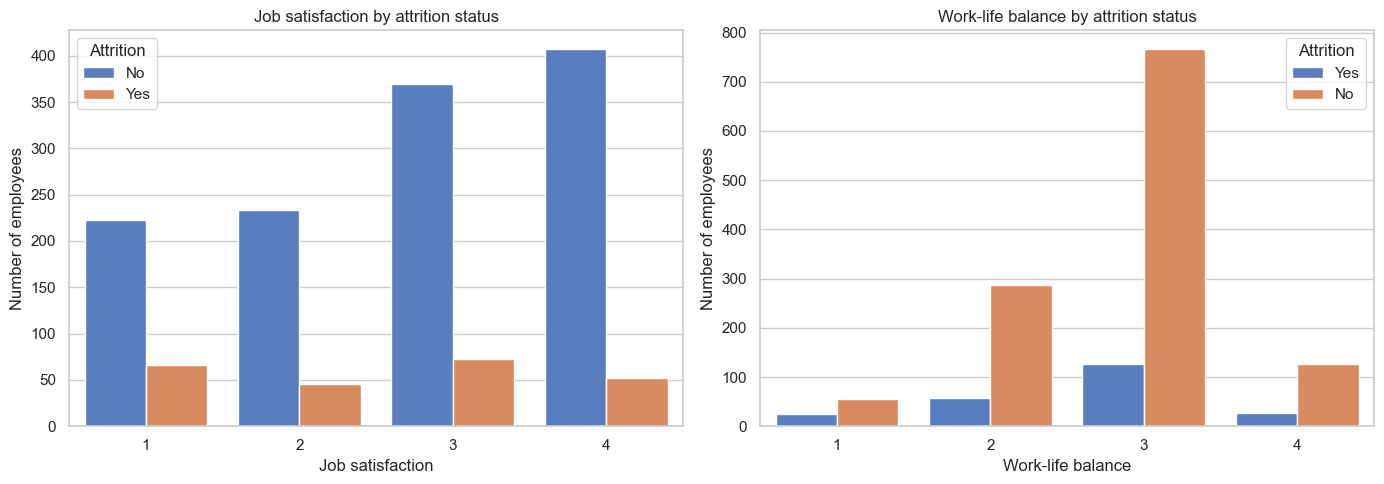

Interpretation:
  Lower satisfaction or poorer work-life balance scores are often associated
  with higher attrition in the sample. These are self-reported categorical
  scores, so they capture perception rather than an objective measure.


In [12]:
# ============================================================
# STEP 4h: Job satisfaction and work-life balance vs attrition
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

satisfaction_cols = ['JobSatisfaction', 'WorkLifeBalance']
labels = ['Job satisfaction', 'Work-life balance']

for col, lab, ax in zip(satisfaction_cols, labels, axes):
    sns.countplot(data=df_clean, x=col, hue='Attrition', ax=ax)
    ax.set_title(f'{lab} by attrition status')
    ax.set_xlabel(lab)
    ax.set_ylabel('Number of employees')
    ax.legend(title='Attrition')

plt.tight_layout()
plt.show()

print('Interpretation:')
print('  Lower satisfaction or poorer work-life balance scores are often associated')
print('  with higher attrition in the sample. These are self-reported categorical')
print('  scores, so they capture perception rather than an objective measure.')


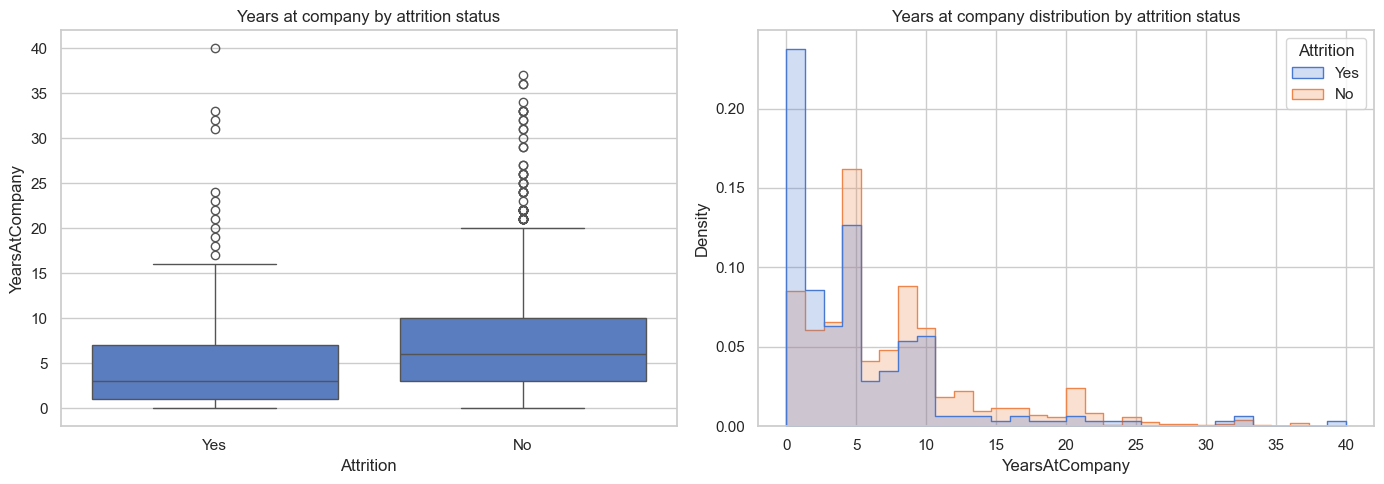

Interpretation:
  Employees with shorter tenure appear more likely to have left in this sample.
  Tenure is partly a function of when attrition happened, so treat it as a
  descriptive association, not a causal lever.


In [13]:
# ============================================================
# STEP 4i: Years at company / tenure vs attrition
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_clean, x='Attrition', y='YearsAtCompany', ax=axes[0])
axes[0].set_title('Years at company by attrition status')
axes[0].set_xlabel('Attrition')
axes[0].set_ylabel('YearsAtCompany')

sns.histplot(data=df_clean, x='YearsAtCompany', hue='Attrition', bins=30,
             element='step', stat='density', common_norm=False, ax=axes[1])
axes[1].set_title('Years at company distribution by attrition status')
axes[1].set_xlabel('YearsAtCompany')
axes[1].set_ylabel('Density')

plt.tight_layout()
plt.show()

print('Interpretation:')
print('  Employees with shorter tenure appear more likely to have left in this sample.')
print('  Tenure is partly a function of when attrition happened, so treat it as a')
print('  descriptive association, not a causal lever.')


Pearson correlation of numerical features with encoded attrition (1=Yes):
DistanceFromHome            0.077924
NumCompaniesWorked          0.043494
MonthlyRate                 0.015170
PerformanceRating           0.002889
HourlyRate                 -0.006846
PercentSalaryHike          -0.013478
Education                  -0.031373
YearsSinceLastPromotion    -0.033019
RelationshipSatisfaction   -0.045872
DailyRate                  -0.056652
TrainingTimesLastYear      -0.059478
WorkLifeBalance            -0.063939
EnvironmentSatisfaction    -0.103369
JobSatisfaction            -0.103481
JobInvolvement             -0.130016
YearsAtCompany             -0.134392
StockOptionLevel           -0.137145
YearsWithCurrManager       -0.156199
Age                        -0.159205
MonthlyIncome              -0.159840
YearsInCurrentRole         -0.160545
JobLevel                   -0.169105
TotalWorkingYears          -0.171063
EmployeeCount                    NaN
StandardHours                    NaN



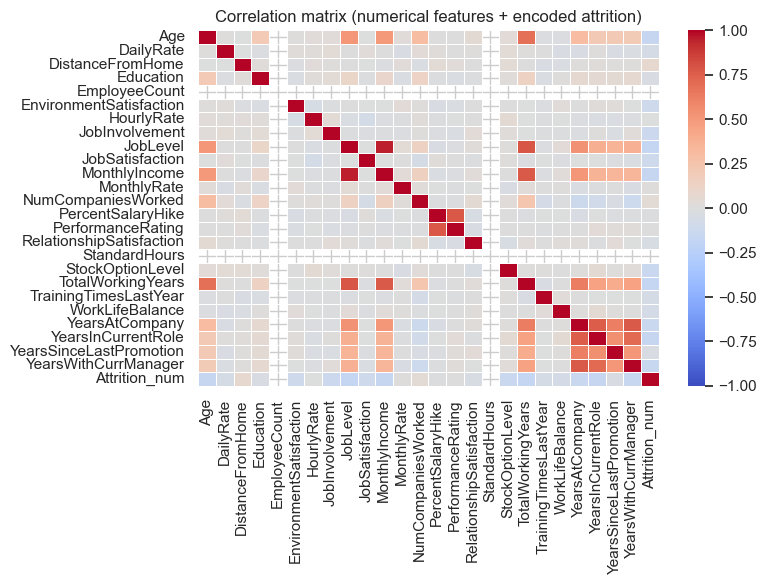

In [14]:
# ============================================================
# STEP 4j: Numerical correlations with the encoded target
# ============================================================
num_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns.tolist()
num_cols = [c for c in num_cols if c not in ID_COLUMNS]

eda_corr = df_clean.copy()
eda_corr['Attrition_num'] = (eda_corr['Attrition'] == 'Yes').astype(int)

corr_targets = num_cols + ['Attrition_num']
corr_matrix = eda_corr[corr_targets].corr()

target_corr = corr_matrix['Attrition_num'].drop('Attrition_num').sort_values(ascending=False)

print('Pearson correlation of numerical features with encoded attrition (1=Yes):')
print(target_corr.to_string())

print('\nInterpretation:')
print('  Correlation is a simple linear association measure. Small or moderate values')
print('  can still matter in combination with other features; large values deserve a')
print('  closer look but still do not imply causation.')

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation matrix (numerical features + encoded attrition)')
plt.tight_layout()
plt.show()


In [15]:
# STEP 5: Feature engineering & preprocessing pipeline
# ============================================================
TARGET_COL = 'Attrition'
ATTR_MAP = {'No': 0, 'Yes': 1}

id_like = [c for c in df_clean.columns if 'Id' in c or 'Number' in c or c.lower() == 'employeenumber']
identifier_cols = [c for c in id_like if df_clean[c].nunique() == len(df_clean)]
constant_cols = [c for c in df_clean.columns if df_clean[c].nunique() <= 1]

exclude_cols = set(identifier_cols) | set(constant_cols) | {TARGET_COL}
X_model = df_clean.drop(columns=[c for c in exclude_cols if c in df_clean.columns]).copy()
y = df_clean[TARGET_COL].map(ATTR_MAP).astype(float).values

numeric_features = X_model.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_features = X_model.select_dtypes(include=['object']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), categorical_features),
    ]
)

print('X_model shape:', X_model.shape)
print('y shape:', y.shape, '| unique:', np.unique(y, return_counts=True))
print('numeric_features:', numeric_features)
print('categorical_features:', categorical_features)
print('excluded cols:', sorted(exclude_cols))
MODEL_COLUMNS = list(X_model.columns)


X_model shape: (1470, 31)
y shape: (1470,) | unique: (array([0., 1.]), array([1233,  237]))
numeric_features: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
categorical_features: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
excluded cols: ['Attrition', 'EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours']


In [16]:
# STEP 6: Train / test split (stratified, fixed seed)
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X_model, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print('Train set size:', len(X_train))
print('Test set size :', len(X_test))
print('Train attrition rate: {:.2f}%'.format(y_train.mean() * 100))
print('Test attrition rate  : {:.2f}%'.format(y_test.mean() * 100))

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc  = preprocessor.transform(X_test)

print()
print('Preprocessed train shape:', X_train_proc.shape)
print('Preprocessed test shape :', X_test_proc.shape)


Train set size: 1176
Test set size : 294
Train attrition rate: 16.16%
Test attrition rate  : 15.99%

Preprocessed train shape: (1176, 51)
Preprocessed test shape : (294, 51)


In [17]:
# STEP 7: Model training with cross-validation comparison
# ============================================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    'LogisticRegression': LogisticRegression(
        class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE
    ),
    'RandomForest': RandomForestClassifier(
        class_weight='balanced', random_state=RANDOM_STATE, n_jobs=1
    ),
    'GradientBoosting': GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
}

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
}

cv_results = {}
for name, model in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model),
    ])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,
                            return_train_score=False)
    cv_results[name] = scores

print('Cross-validation results (mean +/- std over folds):')
header = '{:<22}{:<12}{:<12}{:<12}{:<12}{:<12}'.format(
    'Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC')
print(header)

cv_table = []
for name in models:
    s = cv_results[name]
    row = {
        'Model': name,
        'Accuracy': f"{s['test_accuracy'].mean():.4f} +/- {s['test_accuracy'].std():.4f}",
        'Precision': f"{s['test_precision'].mean():.4f} +/- {s['test_precision'].std():.4f}",
        'Recall': f"{s['test_recall'].mean():.4f} +/- {s['test_recall'].std():.4f}",
        'F1': f"{s['test_f1'].mean():.4f} +/- {s['test_f1'].std():.4f}",
        'ROC_AUC': f"{s['test_roc_auc'].mean():.4f} +/- {s['test_roc_auc'].std():.4f}",
    }
    cv_table.append(row)

cv_df = pd.DataFrame(cv_table)
print(cv_df.to_string(index=False))

print()
print('Interpretation:')
print('  Because the classes are imbalanced, recall and precision matter as much as')
print('  accuracy. A model that misses most leavers can still look accurate.')
print('  We choose a final model based on a balance of recall, precision, F1, and')
print('  ROC-AUC rather than accuracy alone.')


Cross-validation results (mean +/- std over folds):
Model                 Accuracy    Precision   Recall      F1          ROC-AUC     
             Model          Accuracy         Precision            Recall                F1           ROC_AUC
LogisticRegression 0.7534 +/- 0.0309 0.3721 +/- 0.0379 0.7368 +/- 0.0623 0.4925 +/- 0.0337 0.8273 +/- 0.0283
      RandomForest 0.8622 +/- 0.0035 0.8779 +/- 0.1119 0.1842 +/- 0.0526 0.2971 +/- 0.0648 0.8013 +/- 0.0393
  GradientBoosting 0.8716 +/- 0.0138 0.7307 +/- 0.0853 0.3316 +/- 0.0718 0.4514 +/- 0.0755 0.8126 +/- 0.0161

Interpretation:
  Because the classes are imbalanced, recall and precision matter as much as
  accuracy. A model that misses most leavers can still look accurate.
  We choose a final model based on a balance of recall, precision, F1, and
  ROC-AUC rather than accuracy alone.


In [18]:
# STEP 8: Hold-out test evaluation for each model
# ============================================================
test_rows = []
fitted_models = {}

for name, model in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model),
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    cm = confusion_matrix(y_test, y_pred)

    row = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'ROC_AUC': roc_auc_score(y_test, y_prob),
        'ConfusionMatrix': cm.tolist(),
    }
    test_rows.append(row)
    fitted_models[name] = pipe

test_df = pd.DataFrame(test_rows).set_index('Model')
print('Hold-out test results:')
print(test_df.drop(columns=['ConfusionMatrix']).to_string(float_format=lambda v: f'{v:.4f}'))

print()
print('Confusion matrices (rows=true, cols=predicted):')
for r in test_rows:
    print(r['Model'])
    print(pd.DataFrame(r['ConfusionMatrix'], index=['No','Yes'], columns=['No','Yes']))
    print()


Hold-out test results:
                    Accuracy  Precision  Recall     F1  ROC_AUC
Model                                                          
LogisticRegression    0.7517     0.3488  0.6383 0.4511   0.8032
RandomForest          0.8435     0.5556  0.1064 0.1786   0.7878
GradientBoosting      0.8605     0.7143  0.2128 0.3279   0.8051

Confusion matrices (rows=true, cols=predicted):
LogisticRegression
      No  Yes
No   191   56
Yes   17   30

RandomForest
      No  Yes
No   243    4
Yes   42    5

GradientBoosting
      No  Yes
No   243    4
Yes   37   10



Classification report - RandomForest
              precision    recall  f1-score   support

 No (stayed)       0.85      0.98      0.91       247
  Yes (left)       0.56      0.11      0.18        47

    accuracy                           0.84       294
   macro avg       0.70      0.55      0.55       294
weighted avg       0.81      0.84      0.80       294



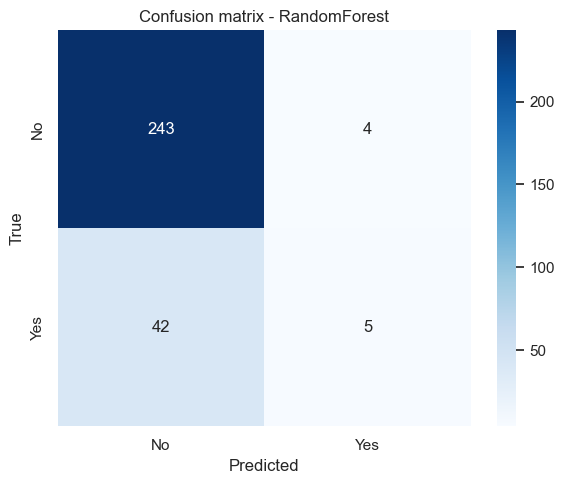

In [19]:
# STEP 8b: Detailed classification report for the chosen model
# ============================================================
chosen_model_name = 'RandomForest'
chosen_pipe = fitted_models[chosen_model_name]

y_pred_chosen = chosen_pipe.predict(X_test)
y_prob_chosen = chosen_pipe.predict_proba(X_test)[:, 1]

print('Classification report -', chosen_model_name)
print(classification_report(y_test, y_pred_chosen,
                            target_names=['No (stayed)', 'Yes (left)'],
                            zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
cm_chosen = confusion_matrix(y_test, y_pred_chosen)
sns.heatmap(cm_chosen, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No','Yes'], yticklabels=['No','Yes'], ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('Confusion matrix - ' + chosen_model_name)
plt.tight_layout()
plt.show()


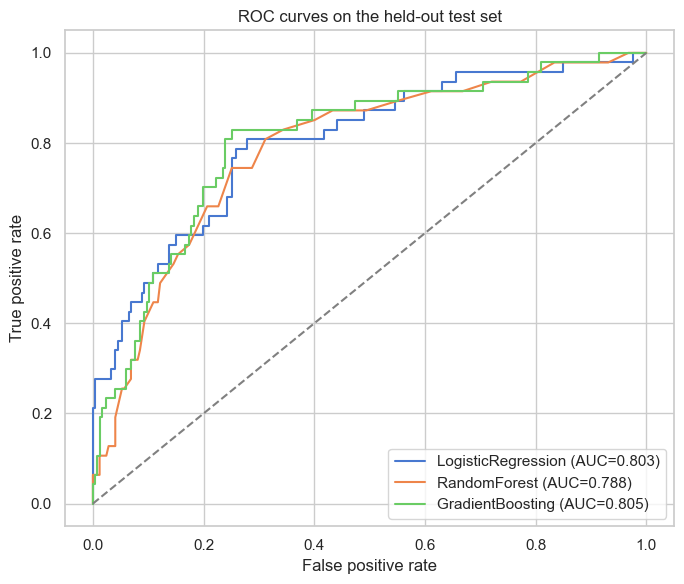

Interpretation:
  ROC-AUC summarizes ranking quality across thresholds. Higher is better,
  but the best threshold for action depends on how costly missed leavers are
  relative to false alarms. That choice is a business decision, not a model one.


In [20]:
# STEP 8c: ROC curve comparison
# ============================================================
fig, ax = plt.subplots(figsize=(7, 6))

for name, pipe in fitted_models.items():
    y_prob = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, y_prob):.3f})')

ax.plot([0, 1], [0, 1], linestyle='--', color='gray')
ax.set_title('ROC curves on the held-out test set')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print('Interpretation:')
print('  ROC-AUC summarizes ranking quality across thresholds. Higher is better,')
print('  but the best threshold for action depends on how costly missed leavers are')
print('  relative to false alarms. That choice is a business decision, not a model one.')


Top 20 predictive features (permutation importance, F1 scoring):
                              feature  mean_importance  std_importance
15                   StockOptionLevel         0.088269        0.017470
18                    WorkLifeBalance         0.063232        0.033058
1                           DailyRate         0.055114        0.015957
0                                 Age         0.043145        0.028805
26         Department_Human Resources         0.041452        0.023527
11                 NumCompaniesWorked         0.041284        0.022053
23          BusinessTravel_Non-Travel         0.033606        0.016907
17              TrainingTimesLastYear         0.027782        0.024562
27  Department_Research & Development         0.023480        0.020923
5                          HourlyRate         0.022418        0.014060
7                            JobLevel         0.022340        0.029057
21            YearsSinceLastPromotion         0.021526        0.016398
28          

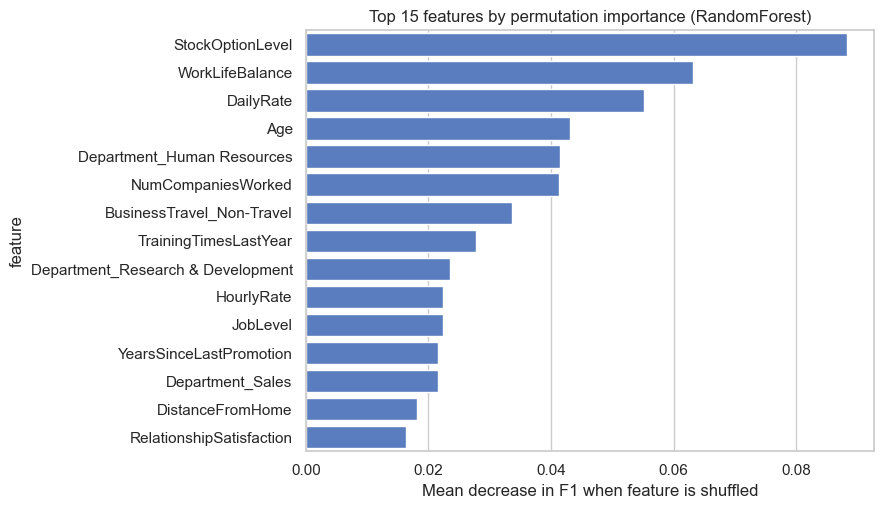


Business-readable interpretation:
  The most influential features in this model are the ones whose values most
  affect predictions on the test set. That does NOT mean they cause attrition.
  It means the model relies on them. Use this to guide further investigation,
  not to make individual employment decisions.


In [21]:
# STEP 9: Model interpretation - permutation importance
# ============================================================
perm = permutation_importance(
    chosen_pipe, X_test, y_test,
    n_repeats=10, random_state=RANDOM_STATE, scoring='f1'
)

ohe = chosen_pipe.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
cat_names = list(ohe.get_feature_names_out(categorical_features))
feature_names = numeric_features + cat_names

n_features = len(feature_names)
mean_imps = np.asarray(perm.importances_mean).ravel()[:n_features]
std_imps  = np.asarray(perm.importances_std).ravel()[:n_features]
m = min(len(feature_names), len(mean_imps), len(std_imps))
feature_names = feature_names[:m]
mean_imps = mean_imps[:m]
std_imps  = std_imps[:m]

perm_df = pd.DataFrame({
    'feature': feature_names,
    'mean_importance': mean_imps,
    'std_importance': std_imps,
}).sort_values('mean_importance', ascending=False)

print('Top 20 predictive features (permutation importance, F1 scoring):')
print(perm_df.head(20).to_string())

top_n = min(15, len(perm_df))
plt.figure(figsize=(9, max(4, top_n * 0.35)))
sns.barplot(data=perm_df.head(top_n), x='mean_importance', y='feature', errorbar=None)
plt.title(f'Top {top_n} features by permutation importance ({chosen_model_name})')
plt.xlabel('Mean decrease in F1 when feature is shuffled')
plt.tight_layout()
plt.show()

print()
print('Business-readable interpretation:')
print('  The most influential features in this model are the ones whose values most')
print('  affect predictions on the test set. That does NOT mean they cause attrition.')
print('  It means the model relies on them. Use this to guide further investigation,')
print('  not to make individual employment decisions.')


In [22]:
# STEP 9b: Logistic Regression coefficients (interpretable baseline)
# ============================================================
lr_pipe = fitted_models['LogisticRegression']
lr = lr_pipe.named_steps['classifier']
lr_ohe = lr_pipe.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
lr_cat_names = list(lr_ohe.get_feature_names_out(categorical_features))
lr_feature_names = numeric_features + lr_cat_names

n_lr_features = len(lr_feature_names)
lr_coef = pd.DataFrame({
    'feature': lr_feature_names,
    'coefficient': lr.coef_.ravel()[:n_lr_features],
}).sort_values('coefficient', ascending=False)

print('Logistic Regression coefficients (positive => associated with higher predicted attrition):')
print(lr_coef.head(15).to_string())
print()
print('... and the lowest 15 ...')
print(lr_coef.tail(15).to_string())

print()
print('Interpretation:')
print('  Positive coefficients push predictions toward Attrition=Yes; negative coefficients')
print('  push toward Attrition=No. Coefficients are on scaled features, so compare them')
print('  with care. They describe the linear baseline, not causal effects.')


Logistic Regression coefficients (positive => associated with higher predicted attrition):
                             feature  coefficient
39     JobRole_Laboratory Technician     1.194333
45      JobRole_Sales Representative     1.120617
24  BusinessTravel_Travel_Frequently     0.787566
50                      OverTime_Yes     0.761522
29    EducationField_Human Resources     0.721129
7                           JobLevel     0.607426
21           YearsSinceLastPromotion     0.502531
38           JobRole_Human Resources     0.463886
11                NumCompaniesWorked     0.460496
48              MaritalStatus_Single     0.457277
28                  Department_Sales     0.356902
34   EducationField_Technical Degree     0.350750
2                   DistanceFromHome     0.318353
19                    YearsAtCompany     0.250725
13                 PerformanceRating     0.140257

... and the lowest 15 ...
                              feature  coefficient
41     JobRole_Manufacturing Di

In [23]:
# STEP 10: Save the best pipeline for later use
# ============================================================
MODEL_DIR = project_root() / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / 'best_attrition_model.pkl'

best_pipeline = chosen_pipe

joblib.dump(best_pipeline, MODEL_PATH)

print('Saved pipeline to:', MODEL_PATH)
print('File exists      :', MODEL_PATH.exists())
print('Model name used  :', chosen_model_name)

loaded = joblib.load(MODEL_PATH)
print('Reloaded object type:', type(loaded).__name__)
print('Has predict        :', hasattr(loaded, 'predict'))
print('Has predict_proba  :', hasattr(loaded, 'predict_proba'))


Saved pipeline to: D:\Data Analyst\Employee-Attrition-AI\models\best_attrition_model.pkl
File exists      : True
Model name used  : RandomForest
Reloaded object type: Pipeline
Has predict        : True
Has predict_proba  : True


In [24]:
# STEP 11: Example prediction on a valid sample record
# ============================================================
sample = pd.DataFrame(columns=MODEL_COLUMNS)
sample['Age'] = [32]
sample['BusinessTravel'] = ['Travel_Rarely']
sample['DailyRate'] = [800]
sample['Department'] = ['Sales']
sample['DistanceFromHome'] = [5]
sample['Education'] = [3]
sample['EducationField'] = ['Life Sciences']
sample['EnvironmentSatisfaction'] = [3]
sample['Gender'] = ['Male']
sample['HourlyRate'] = [60]
sample['JobInvolvement'] = [3]
sample['JobLevel'] = [2]
sample['JobRole'] = ['Sales Executive']
sample['JobSatisfaction'] = [3]
sample['MonthlyIncome'] = [4500]
sample['MonthlyRate'] = [11000]
sample['NumCompaniesWorked'] = [2]
sample['OverTime'] = ['No']
sample['PercentSalaryHike'] = [12]
sample['PerformanceRating'] = [3]
sample['RelationshipSatisfaction'] = [3]
sample['StockOptionLevel'] = [1]
sample['TotalWorkingYears'] = [6]
sample['TrainingTimesLastYear'] = [3]
sample['WorkLifeBalance'] = [3]
sample['YearsAtCompany'] = [4]
sample['YearsInCurrentRole'] = [2]
sample['YearsSinceLastPromotion'] = [1]
sample['YearsWithCurrManager'] = [2]

assert set(sample.columns) == set(MODEL_COLUMNS), 'Sample columns still do not match MODEL_COLUMNS.'
assert sample.shape[1] == len(MODEL_COLUMNS), 'Sample column count mismatch.'

pred_class = loaded.predict(sample)[0]
pred_label = 'Yes (likely to leave)' if pred_class == 1 else 'No (likely to stay)'
pred_prob = loaded.predict_proba(sample)[0]

print('Sample input (single record):')
print(sample.T)
print()
print('Prediction class (0=No, 1=Yes):', int(pred_class))
print('Predicted label                :', pred_label)
print('Probability No / Yes           : {:.3f} / {:.3f}'.format(float(pred_prob[0]), float(pred_prob[1])))

print()
print('IMPORTANT:')
print('  This is an educational estimate from a model trained on fictional data.')
print('  It is NOT a validated employment decision tool and must not be used as the')
print('  sole basis for any decision about a real person.')


Sample input (single record):
                                        0
Age                                    32
BusinessTravel              Travel_Rarely
DailyRate                             800
Department                          Sales
DistanceFromHome                        5
Education                               3
EducationField              Life Sciences
EnvironmentSatisfaction                 3
Gender                               Male
HourlyRate                             60
JobInvolvement                          3
JobLevel                                2
JobRole                   Sales Executive
JobSatisfaction                         3
MaritalStatus                         NaN
MonthlyIncome                        4500
MonthlyRate                         11000
NumCompaniesWorked                      2
OverTime                               No
PercentSalaryHike                      12
PerformanceRating                       3
RelationshipSatisfaction                3
Stoc

In [25]:
# ============================================================
# STEP 12: Limitations and closing notes
# ============================================================
print('KEY LIMITATIONS')
print('-' * 60)
print('1. The dataset is fictional and may not reflect any real organization.')
print('2. Associations are not causation. Predictive importance is not proof of cause.')
print('3. The model is trained on historical patterns; future attrition can differ.')
print('4. Class imbalance affects metric interpretation; accuracy alone is misleading.')
print('5. This model is not validated for real HR decisions.')
print('6. Ethical use matters: predictions should support investigation, not label people.')
print('\nCLOSING NOTE')
print('-' * 60)
print('This notebook is the main analytical deliverable. A Streamlit dashboard and a')
print('Word report can be built from these results. If you rerun the notebook, the')
print('saved model and any report should be regenerated from the fresh run.')


KEY LIMITATIONS
------------------------------------------------------------
1. The dataset is fictional and may not reflect any real organization.
2. Associations are not causation. Predictive importance is not proof of cause.
3. The model is trained on historical patterns; future attrition can differ.
4. Class imbalance affects metric interpretation; accuracy alone is misleading.
5. This model is not validated for real HR decisions.
6. Ethical use matters: predictions should support investigation, not label people.

CLOSING NOTE
------------------------------------------------------------
This notebook is the main analytical deliverable. A Streamlit dashboard and a
Word report can be built from these results. If you rerun the notebook, the
saved model and any report should be regenerated from the fresh run.
